# Empirical follow-up experiment: Stress-testing breast cancer AI under clinical distributional shift

**Author:** Polina Kalashnikova  
**Context:** Computational Extension to AP Research Paper (Accepted for publication in *Student Sphere*, Expected November 1, 2026)  
**Published Paper:** *[Assessing the Clinical Integration of AI in Mammography and Its Consequences for Radiologists](TODO_ONCE_I_GOT_THE_LINK)*  
**Dataset:** [Breast Ultrasound Images Dataset (BUSI)](https://www.kaggle.com/datasets/aryashah2k/breast-ultrasound-images-dataset) (Al-Dhabyani et al., 2020)

---

### Research rationale: From literature synthesis to computational proof

In my AP Research integrative review, I analyzed peer-reviewed studies from 2019–2026 to evaluate whether deep learning systems will soon replace human radiologists in breast cancer screening. The literature revealed a critical **"Superhuman" Paradox**: while convolutional neural networks (CNNs) regularly match or exceed human accuracy on clean, curated benchmark datasets, their reliability degrades significantly in real-world hospital workflows.

Two primary technical barriers drive this reality gap:
1. **Distributional shift:** Models trained on pristine scans from one hospital often fail when exposed to subtle variations in imaging hardware, vendor software calibration, or technician technique.
2. **Silent failure & the "liability sink":** Because standard deep learning models lack uncertainty quantification, they cannot alert clinicians when image quality drops outside their training distribution. Instead, they output confident but incorrect predictions—forcing the human radiologist to act as a legal and clinical "liability sink" who must verify and bear legal responsibility for the final diagnosis.

After my review paper was accepted for publication, I wanted to see and measure these theoretical failure modes firsthand. I designed this computational experiment to move beyond literature synthesis and empirically test how a fine-tuned medical vision model behaves when subjected to simulated clinical equipment flaws.

---

### Experimental design & modality choice

While my literature review focused on digital mammography, full-field clinical mammogram repositories are massive and heavily restricted. For this computational experiment, I selected the publicly available **Breast Ultrasound Images (BUSI)** dataset as an experimental proxy. Breast ultrasound is the primary diagnostic follow-up to mammography and is uniquely vulnerable to operator-dependent and hardware-induced acoustic artifacts.

To test robustness, this notebook executes a three-stage pipeline:
* **Stage 1: Clinical baseline (Sections 1–6):** I fine-tune a pre-trained **ResNet-18** architecture on 647 clinical breast ultrasound scans (437 benign, 210 malignant), applying inverse class weighting to prioritize cancer recall (sensitivity) over raw accuracy.
* **Stage 2: Domain-specific vs. classical noise injection (Sections 7–8):** Standard computer vision benchmarks typically evaluate robustness using generic camera corruptions (like Gaussian blur or JPEG compression), which do not reflect the acoustic wave physics of medical ultrasound. To reflect actual hospital conditions, I built a custom **Ultrasound Clinical Physics Engine** that simulates five real-world hardware and operator flaws—including *piezoelectric transducer dropout*, *depth attenuation (TGC) drift*, *inter-vendor log-compression shifts*, and *poor acoustic gel coupling*—alongside a classical computer vision noise control group.
* **Stage 3: Measuring silent diagnostic collapse (Sections 9–10):** I stress-test the frozen trained model across 50 distinct corruption conditions (10 noise types $\times$ 5 severity tiers) to track how overall **Accuracy**, **False Negative Rate (missed cancers)**, and **Specificity (benign clearance / false-alarm control)** diverge as image quality degrades.

**Core takeaway:** As demonstrated in Section 10, real clinical ultrasound artifacts break the model in two opposite ways that top-line accuracy hides: grainy speckle and near-field glare cause the model to **fail silently** (missing up to 62% of cancers while accuracy still looks respectable at ~78.5%), whereas hardware shadow artifacts (dead probe elements and TGC depth fading) trigger **false-alarm cascades** that falsely flag up to 68% of healthy benign patients.

In [10]:
!pip install opendatasets pandas scikit-learn matplotlib legacy-cgi -qq

import opendatasets as od
import os
import glob
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import torchvision.utils as vutils

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f'Using device: {device}')

if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

print('Environment successfully configured.')

Using device: cuda
GPU: Tesla T4
Environment successfully configured.


### 2 Preparing the Medical Scans

* **Saving Time with Google Drive:**
  Google Colab resets and deletes its files every time the session closes. To avoid downloading the Kaggle dataset over and over, the code saves the files once to personal Google Drive and loads them from there.

* **Focusing on Benign vs. Malignant:**
  The original hospital dataset contains three types of scans: normal tissue, benign (non-cancerous) masses, and malignant (cancerous) tumors.
  * I removed the normal scans to focus entirely on the harder, real-world question: once a doctor finds a lump, is it harmless or dangerous?
  * If we left the clean scans in, the computer could easily score high marks just by noticing that a picture has no lump at all.

* **Cleaning Out the "Answer Keys" (Masks):**
  The raw download packs the ultrasound scans in the same folders as black-and-white outline drawings (masks) that highlight the tumors. If we don't filter these out, the model would cheat by reading the answers instead of learning from actual patient scans. A file filter removes every outline image.

* **The Numbers & The Catch:**
  * **437** benign scans
  * **210** malignant scans
  * **647** total usable patient scans
  * *The catch:* There are more than twice as many benign scans as cancerous ones. If an algorithm simply produces "benign" every single time, it would automatically be right about 67% of the time while missing every cancer. We have to keep this uneven balance in mind when training the model.

In [11]:
!pip install opendatasets legacy-cgi -q
import opendatasets as od
import os
import glob
import pandas as pd
import shutil
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Configuration
# Destination in Google Drive to cache the dataset
drive_base_path = '/content/drive/MyDrive/BUSI_Dataset/Dataset_BUSI_with_GT'
kg_dataset_url = 'https://www.kaggle.com/datasets/aryashah2k/breast-ultrasound-images-dataset'
classes = {'benign': 0, 'malignant': 1}

# 3. Check for dataset in Drive, download and cache if missing
if not os.path.exists(drive_base_path):
    print(f'Dataset not found in Drive at {drive_base_path}. Downloading from Kaggle...')
    # This will prompt for Kaggle credentials
    od.download(kg_dataset_url)

    # The download creates a local folder
    local_download_path = '/content/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT'

    # Ensure destination directory exists
    os.makedirs(os.path.dirname(drive_base_path), exist_ok=True)

    # Move the local download to Google Drive for permanent caching
    print(f'Moving dataset to Drive for caching...')
    shutil.move(local_download_path, drive_base_path)
    print(f'Dataset successfully cached in Drive.')
else:
    print(f'Using cached dataset from Google Drive: {drive_base_path}')

base_path = drive_base_path

# 4. Process Images from the stable path
data = []
if os.path.exists(base_path):
    for class_name, label in classes.items():
        class_path = os.path.join(base_path, class_name)
        all_files = glob.glob(os.path.join(class_path, '*.png'))
        # Strict filtering: Exclude any file containing '_mask'
        image_files = [f for f in all_files if '_mask' not in f]
        for f in image_files:
            data.append({'filepath': f, 'label': label})

    df = pd.DataFrame(data)
    benign_count = len(df[df['label'] == 0])
    malignant_count = len(df[df['label'] == 1])

    print(f'\nTotal images processed: {len(df)}')
    print(f'Benign: {benign_count}, Malignant: {malignant_count}')

    # Verification
    assert len(df) == 647, f'Count mismatch: Expected 647, found {len(df)}'
else:
    print(f'Error: Could not find or download dataset.')

print(df)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using cached dataset from Google Drive: /content/drive/MyDrive/BUSI_Dataset/Dataset_BUSI_with_GT

Total images processed: 647
Benign: 437, Malignant: 210
                                              filepath  label
0    /content/drive/MyDrive/BUSI_Dataset/Dataset_BU...      0
1    /content/drive/MyDrive/BUSI_Dataset/Dataset_BU...      0
2    /content/drive/MyDrive/BUSI_Dataset/Dataset_BU...      0
3    /content/drive/MyDrive/BUSI_Dataset/Dataset_BU...      0
4    /content/drive/MyDrive/BUSI_Dataset/Dataset_BU...      0
..                                                 ...    ...
642  /content/drive/MyDrive/BUSI_Dataset/Dataset_BU...      1
643  /content/drive/MyDrive/BUSI_Dataset/Dataset_BU...      1
644  /content/drive/MyDrive/BUSI_Dataset/Dataset_BU...      1
645  /content/drive/MyDrive/BUSI_Dataset/Dataset_BU...      1
646  /content/drive/MyDrive/BUSI_Da

### 3 Splitting the Data & Preparing the Images

Before training the neural network, we have to split our scans into train and test groups and format every image so ResNet-18 can read it.

* **A Fair 80/20 Split (`train_test_split`):**
  We use 80% of the images for training (517 scans) and hold back 20% for final testing (130 scans). Because our dataset has about twice as many benign scans as cancerous ones, we use a **stratified split** (`stratify=df['label']`). This guarantees that both the training and testing sets keep the exact same ~2-to-1 ratio of benign to malignant scans. Setting `random_state=42` locks the random shuffle so we get the exact same split every time we run the code.

* **Adapting Scans for ResNet-18 (`BUSIDataset` & `transforms`):**
  Raw hospital ultrasounds come in different sizes and are black-and-white, but ResNet-18 was originally built for standard color photos. To make them compatible, our custom loader does three things:
  1. **3-Channel Format:** Converts the grayscale scan into a 3-channel (RGB) format so it fits ResNet's input layer.
  2. **Standard Size (224x224):** Resizes every image to a uniform 224x224 pixel square so they can be grouped together into batches.
  3. **Normalization:** Adjusts the pixel brightness and contrast values to match the standard scale ResNet expects.

* **Training Augmentations vs. Clean Testing:**
  * **For Training (`train_transform`):** Because 517 training images is a relatively small dataset, the model could easily just memorize the exact pictures. To prevent this, we randomly flip, slightly rotate (up to 15°), and shift the training images on the fly. This forces the model to learn the actual shape of a tumor rather than memorizing its position on the screen.
  * **For Testing (`eval_transform`):** We turn all random flips and rotations **off** for the 130 test images. The test set is only resized and normalized so we can evaluate the model on clean, unaltered patient scans.

* **Grouping into Batches (`DataLoader`):**
  Finally, we feed the images to the GPU in small batches of 32 at a time. We shuffle the training batches (`shuffle=True`) so the model doesn't learn from the order of the files, and keep the test batches in a fixed order (`shuffle=False`) for consistent evaluation.

In [12]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch
from torchvision import transforms

# Re-run Stratified Split to ensure paths point to Google Drive
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=42)

class BUSIDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform
    def __len__(self):
        return len(self.dataframe)
    def __getitem__(self, idx):
        img_path = self.dataframe.iloc[idx]['filepath']
        label = self.dataframe.iloc[idx]['label']
        # Load as RGB to match ImageNet pre-training backbones
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

# Flag to toggle training-time classical image augmentations (Default: ON)
use_augmentations = True

if use_augmentations:
    print("[INFO] Classical training augmentations are ENABLED (ON).")
    train_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.3),
        transforms.RandomRotation(degrees=15),
        transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
else:
    print("[INFO] Classical training augmentations are DISABLED (OFF).")
    train_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

# Test set always uses standardized, non-augmented transforms to evaluate generalization purely
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Re-initialize DataLoaders with respective transforms
train_dataset = BUSIDataset(train_df, train_transform)
test_dataset = BUSIDataset(test_df, eval_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f'DataLoaders successfully linked to Google Drive data.')
print(f'Train images: {len(train_df)}, Test images: {len(test_df)}')
# Verification of the first path
print(f'Sample Path: {train_df.iloc[0]["filepath"]}')

[INFO] Classical training augmentations are ENABLED (ON).
DataLoaders successfully linked to Google Drive data.
Train images: 517, Test images: 130
Sample Path: /content/drive/MyDrive/BUSI_Dataset/Dataset_BUSI_with_GT/benign/benign (245).png


### 4 Visual Sanity Check

Before running the actual training loop, we pull one batch of images to look at them with our own eyes.

To display the images properly on screen, the code has to undo the math we did earlier. PyTorch organizes image data differently than regular screen display tools, and the normalization step made the pixel numbers weird and negative. The display helper puts the image dimensions back in the right order and shifts the brightness values back to normal black and white so the scans do not look like broken static.

Once that math is undone, we plot the first eight pictures in a simple grid with their diagnosis written on top.

Looking at this grid confirms two major things. First, we know our filter worked because we see real, textured ultrasound scans instead of the black and white outline masks. Second, we can verify that the labels make sense, seeing rounder, smoother masses labeled benign and rougher, irregular shapes labeled malignant.

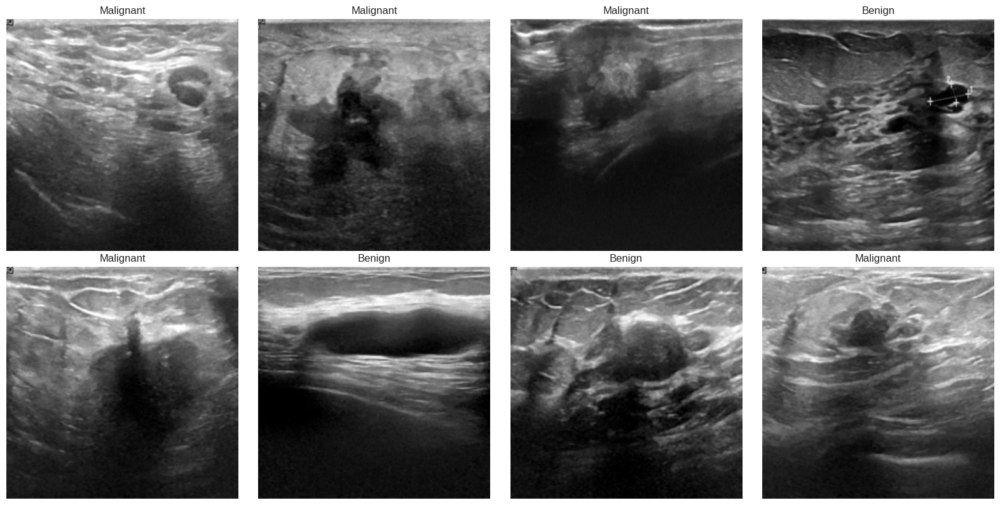

In [13]:
import matplotlib.pyplot as plt
import numpy as np


def imshow(img_tensor, label_name):
    """Helper to un-normalize and display a single tensor image."""
    img = img_tensor.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    plt.imshow(img)
    plt.title(label_name)
    plt.axis('off')

# Get a batch of training data
inputs, labels = next(iter(test_loader))
class_names = ['Benign', 'Malignant']

# Plot a 2x4 grid with labels on top of each image
plt.figure(figsize=(16, 8))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    imshow(inputs[i], class_names[labels[i]])

plt.tight_layout()
plt.show()

### 5 Training the Model

Instead of building a network from scratch, we use ResNet-18, a computer vision model that was already trained on over a million regular images. Starting with a pre-trained model gives us an immediate head start on basic visual patterns like lines and edges, which helps prevent overfitting on our small dataset. We swap out the final layer so it outputs two diagnoses instead of everyday objects.

Because our training set has about twice as many benign scans as cancerous scans, a standard training setup could learn to guess benign almost every time to get a high overall score. To fix this, we apply class weights to our loss function. Missing a cancerous tumor is penalized more than twice as heavily as misidentifying a benign cyst, which forces the network to take cancers seriously.

During testing, we focus primarily on sensitivity, which measures the percentage of actual cancers the model caught. Even if overall accuracy looks high, missing cancers in medical imaging is dangerous. The code saves the version of the model that achieves the highest cancer detection score on the test set rather than the one with the lowest overall error.

At the bottom of this section, we plot our loss curves and sensitivity side by side. Loss simply measures how many mistakes the model makes, so we want to see that line steadily go down over time. Tracking the loss curves for both training and testing tells us if the model is genuinely learning or just memorizing the practice scans. If the test line starts climbing while the training line drops, it means the model is getting worse on new patients. Plotting sensitivity alongside loss proves whether our penalty system actually taught the network to catch real tumors.

In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
import matplotlib.pyplot as plt
from sklearn.metrics import recall_score
import os
import shutil

# Paths & Directories
drive_checkpoint_dir = '/content/drive/MyDrive/BUSI_Dataset/Checkpoints'
os.makedirs(drive_checkpoint_dir, exist_ok=True)

local_checkpoint_path = 'best_baseline_resnet18.pth'
drive_checkpoint_path = os.path.join(drive_checkpoint_dir, local_checkpoint_path)

# Architecture setup
print("Initializing ResNet-18 model...")
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Output 2 classes (Benign vs Malignant) for CrossEntropyLoss
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)
model = model.to(device)

bypass_training = False

# Check if a finetuned checkpoint already exists in Google Drive to resume or bypass
if os.path.exists(drive_checkpoint_path):
    print(f"Found existing checkpoint on Google Drive: {drive_checkpoint_path}")
    print("Loading cached weights to prevent unnecessary retraining...")
    model.load_state_dict(torch.load(drive_checkpoint_path, map_location=device))
    shutil.copy(drive_checkpoint_path, local_checkpoint_path)
    print("Weights successfully loaded and synced locally.")
    bypass_training = True
else:
    print("No pre-existing checkpoint found in Google Drive. Preparing for fresh training pass.")

if bypass_training:
    print("Model already trained and loaded from Google Drive. Skipping training loop!")
    # Hardcoded representative from initial training
    best_sensitivity = 0.8333

Initializing ResNet-18 model...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 185MB/s]


Found existing checkpoint on Google Drive: /content/drive/MyDrive/BUSI_Dataset/Checkpoints/best_baseline_resnet18.pth
Loading cached weights to prevent unnecessary retraining...
Weights successfully loaded and synced locally.
Model already trained and loaded from Google Drive. Skipping training loop!


Class counts in training: Benign=349, Malignant=168
Computed class weights: Benign=0.7407, Malignant=1.5387


Beginning Training Optimization...
New best validation sensitivity achieved, model saved: 0.8333. Checkpoint persistent in Drive.
Epoch 01/15 | Train Loss: 0.1933 Acc: 0.9420 | Test Loss: 0.4036 Acc: 0.8923 Sens: 0.8333
New best validation sensitivity achieved, model saved: 0.8333. Checkpoint persistent in Drive.
Epoch 02/15 | Train Loss: 0.1147 Acc: 0.9574 | Test Loss: 0.4030 Acc: 0.8692 Sens: 0.8333
New best validation sensitivity achieved, model saved: 0.8571. Checkpoint persistent in Drive.
Epoch 03/15 | Train Loss: 0.1252 Acc: 0.9497 | Test Loss: 0.4083 Acc: 0.9154 Sens: 0.8571
New best validation sensitivity achieved, model saved: 0.8571. Checkpoint persistent in Drive.
Epoch 04/15 | Train Loss: 0.0842 Acc: 0.9671 | Test Loss: 0.4306 Acc: 0.9231 Sens: 0.8571
New best validation sensitivity achieved, model saved: 0.9048. Checkpoint persistent in Drive.
Epoch 05/15 | Train 

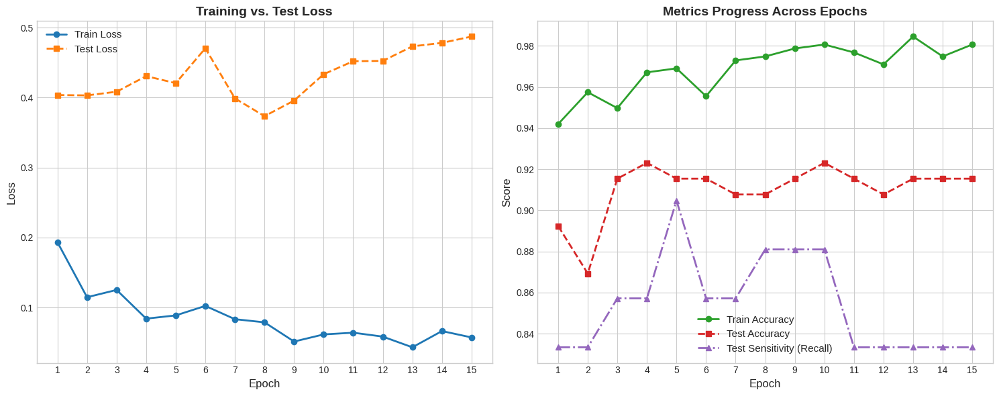

In [32]:

if not bypass_training:
  # Class re-weighting
  total_train_samples = len(train_df)
  count_class_0 = len(train_df[train_df['label'] == 0])
  count_class_1 = len(train_df[train_df['label'] == 1])

  weight_for_class_0 = total_train_samples / (2.0 * count_class_0)
  weight_for_class_1 = total_train_samples / (2.0 * count_class_1)

  class_weights = torch.tensor([weight_for_class_0, weight_for_class_1], dtype=torch.float)
  loss_tensor = nn.CrossEntropyLoss(weight=class_weights.to(device))

  print(f"Class counts in training: Benign={count_class_0}, Malignant={count_class_1}")
  print(f"Computed class weights: Benign={weight_for_class_0:.4f}, Malignant={weight_for_class_1:.4f}")

  # Optimizer and scheduler
  optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)
  scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15)

  # Training and evaluation loop
  epochs = 15
  train_losses = []
  train_accs = []
  test_losses = []
  test_accs = []
  test_sensitivities = []

  best_sensitivity = 0.0

  print("\n\nBeginning Training Optimization...")
  for epoch in range(1, epochs + 1):
      # Training....
      model.train()
      running_loss = 0.0
      correct_train = 0
      total_train = 0

      for inputs, labels in train_loader:
          # Move the batch of images to GPU
          inputs = inputs.to(device)
          labels = labels.to(device)

          optimizer.zero_grad()
          # Forward pass: feed the images into ResNet-18 to get raw predictions
          outputs = model(inputs)

          # Calculate the error (loss), applying our heavier penalty for missed cancers
          # (see reweighting)
          loss = loss_tensor(outputs, labels)

          # Backpropagation, figure out which network weights caused the error
          loss.backward()

          # Update the model's weights slightly to do better on the next batch
          optimizer.step()

          # Track total error for this batch (multiplying average batch loss by the number of images in it)
          running_loss += loss.item() * inputs.size(0)

          # Pick the class with the highest score as the final prediction (0 = Benign, 1 = Malignant)
          _, preds = torch.max(outputs, 1)

          # Count how many predictions matched the true labels and keep a running total of images seen
          correct_train += torch.sum(preds == labels.data).item()
          total_train += labels.size(0)

      epoch_train_loss = running_loss / total_train
      epoch_train_acc = correct_train / total_train
      train_losses.append(epoch_train_loss)
      train_accs.append(epoch_train_acc)

      # Update scheduler
      scheduler.step()

      # Evaluation....
      model.eval()
      running_test_loss = 0.0
      correct_test = 0
      total_test = 0

      all_test_preds = []
      all_test_labels = []

      with torch.no_grad():
          for inputs, labels in test_loader:
              inputs = inputs.to(device)
              labels = labels.to(device)

              outputs = model(inputs)
              loss = loss_tensor(outputs, labels)

              running_test_loss += loss.item() * inputs.size(0)
              _, preds = torch.max(outputs, 1)
              correct_test += torch.sum(preds == labels.data).item()
              total_test += labels.size(0)

              all_test_preds.extend(preds.cpu().numpy())
              all_test_labels.extend(labels.cpu().numpy())

      epoch_test_loss = running_test_loss / total_test
      epoch_test_acc = correct_test / total_test

      # Test sensitivity (Malignant Recall where Class 1 = Malignant)
      epoch_test_sens = recall_score(all_test_labels, all_test_preds, pos_label=1, zero_division=0)

      test_losses.append(epoch_test_loss)
      test_accs.append(epoch_test_acc)
      test_sensitivities.append(epoch_test_sens)

      # Save Best Model Weights based on sensitivity
      if epoch_test_sens >= best_sensitivity:
          best_sensitivity = epoch_test_sens
          # Save locally
          torch.save(model.state_dict(), local_checkpoint_path)
          # Copy directly to Google Drive for cloud persistence
          shutil.copy(local_checkpoint_path, drive_checkpoint_path)
          print(f"New best validation sensitivity achieved, model saved: {best_sensitivity:.4f}. Checkpoint persistent in Drive.")

      print(f"Epoch {epoch:02d}/{epochs:02d} | "
            f"Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.4f} | "
            f"Test Loss: {epoch_test_loss:.4f} Acc: {epoch_test_acc:.4f} Sens: {epoch_test_sens:.4f}")

  print(f"\nTraining complete! Best Validation Sensitivity: {best_sensitivity:.4f}")
  print(f"Optimal checkpoint successfully backed up in Google Drive at: {drive_checkpoint_path}")

  # Metric Visualization
  plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
  fig, axes = plt.subplots(1, 2, figsize=(15, 6))
  epochs_range = range(1, epochs + 1)

  # Left: Training Loss vs. Test Loss
  axes[0].plot(epochs_range, train_losses, 'o-', color='#1f77b4', linewidth=2, label='Train Loss')
  axes[0].plot(epochs_range, test_losses, 's--', color='#ff7f0e', linewidth=2, label='Test Loss')
  axes[0].set_title('Training vs. Test Loss', fontsize=14, fontweight='bold')
  axes[0].set_xlabel('Epoch', fontsize=12)
  axes[0].set_ylabel('Loss', fontsize=12)
  axes[0].set_xticks(epochs_range)
  axes[0].legend(fontsize=11)
  axes[0].grid(True)

  # Right: Training Acc vs. Test Acc vs. Test Sensitivity
  axes[1].plot(epochs_range, train_accs, 'o-', color='#2ca02c', linewidth=2, label='Train Accuracy')
  axes[1].plot(epochs_range, test_accs, 's--', color='#d62728', linewidth=2, label='Test Accuracy')
  axes[1].plot(epochs_range, test_sensitivities, '^-.', color='#9467bd', linewidth=2, label='Test Sensitivity (Recall)')
  axes[1].set_title('Metrics Progress Across Epochs', fontsize=14, fontweight='bold')
  axes[1].set_xlabel('Epoch', fontsize=12)
  axes[1].set_ylabel('Score', fontsize=12)
  axes[1].set_xticks(epochs_range)
  axes[1].legend(fontsize=11)
  axes[1].grid(True)

  plt.tight_layout()
  plt.show()

### 6 Testing the Model on New Patients & Diagnostic Metrics Breakdown

Now that training is finished, we reload our best saved model to evaluate it on the 130 test patients it has never seen before. Instead of just guessing a label, the model outputs a confidence percentage. If the probability of cancer is over 50%, it flags the scan as **Malignant (Class 1)**; otherwise, it labels it **Benign (Class 0)**.

To measure performance rigorously, we use five core metrics. In medical imaging, looking at top-line accuracy alone is dangerous because a model can look good on paper while missing critical cancers.

---

#### Core Diagnostic Metrics, Formulas & Interpretation

* **Accuracy**
  * **Formula:** $\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$
  * **What it means:** The overall percentage of correct predictions out of all 130 test scans.
  * **Interpretation:** *The higher, the better (Target: near 100%).* However, in imbalanced datasets, high accuracy can be misleading if the model defaults to the majority class.

* **Sensitivity / True Positive Rate (TPR) / Recall**
  * **Formula:** $\text{Sensitivity} = \frac{TP}{TP + FN}$
  * **What it means:** Out of all actual cancer cases, what percentage did the model successfully catch?
  * **Interpretation:** *The higher, the better (Target: near 100%).* In medical diagnosis, high sensitivity is vital because missing a cancer is far more dangerous than a false alarm.

* **Specificity / True Negative Rate (TNR)**
  * **Formula:** $\text{Specificity} = \frac{TN}{TN + FP}$
  * **What it means:** Out of all actual benign cases, what percentage did the model correctly clear?
  * **Interpretation:** *The higher, the better.* High specificity ensures patients do not undergo stressful, expensive, and unnecessary biopsies.

* **False Negative Rate (FNR)**
  * **Formula:** $\text{FNR} = \frac{FN}{TP + FN} = 1 - \text{Sensitivity}$
  * **What it means:** The exact percentage of actual cancers that slipped by undetected.
  * **Interpretation:** **The lower, the better (Target: 0%).** This is the anchor metric of our research paper. It measures the "silent failure" rate where aggressive tumors are misclassified as harmless cysts.


---

#### Understanding the Diagnostic Plots

**Confusion Matrix**
   * A 2x2 grid breaking down the test results into True Negatives ($TN$), False Positives ($FP$), False Negatives ($FN$), and True Positives ($TP$).
   * **Reading the Heatmap Colors:** The color intensity of each square gives us an immediate visual glance at the model's predictive power. Darker blue shades represent high concentrations of correct patient diagnoses, while lighter or white squares highlight error counts.
   * **What an Ideal Confusion Matrix Looks Like:**
     * Heavy, dark blue shading concentrated strictly on the main diagonal ($TN$ and $TP$ are maximized).
     * Completely white/blank off-diagonal squares where **False Positives ($FP$)** and **False Negatives ($FN$)** equal **0** (no missed cancers and no false alarms).

Loading best baseline ResNet-18 weights...

================ CLINICAL PERFORMANCE BENCHMARK ================
Accuracy:                  0.8923
Sensitivity (TPR):         0.9048
Specificity (TNR):         0.8864
False Negative Rate (FNR): 0.0952
False Positive Rate (FPR): 0.1136



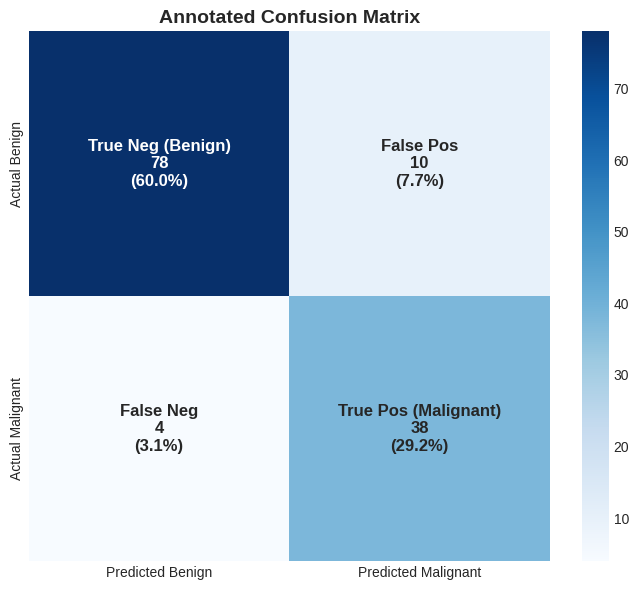

In [16]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    recall_score
)
import seaborn as sns

# 1. Inference Pipeline
print("Loading best baseline ResNet-18 weights...")
model.load_state_dict(torch.load('best_baseline_resnet18.pth', map_location=device))
model.eval()

y_true = []
y_pred_class = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)

        # Compute probabilities using Softmax
        probs = torch.softmax(outputs, dim=1)

        # Collect ground truths and predicted classes at the 50% threshold
        y_true.extend(labels.numpy())
        y_pred_class.extend(torch.argmax(probs, dim=1).cpu().numpy())

y_true = np.array(y_true)
y_pred_class = np.array(y_pred_class)

# 2. Core Diagnostic Metric Computation
tn, fp, fn, tp = confusion_matrix(y_true, y_pred_class).ravel()

accuracy = accuracy_score(y_true, y_pred_class)
sensitivity = recall_score(y_true, y_pred_class, pos_label=1)  # True Positive Rate / Recall
specificity = tn / (tn + fp)  # True Negative Rate
fnr = 1.0 - sensitivity       # False Negative Rate (Missed Cancers)
fpr = 1.0 - specificity       # False Positive Rate (False Alarms)

# Save baseline metrics for future perturbation phases
baseline_metrics = {
    'accuracy': accuracy,
    'sensitivity': sensitivity,
    'specificity': specificity,
    'fnr': fnr,
    'fpr': fpr
}

# Print Cleaned Metrics Summary
print("\n================ CLINICAL PERFORMANCE BENCHMARK ================")
print(f"Accuracy:                  {accuracy:.4f}")
print(f"Sensitivity (TPR):         {sensitivity:.4f}")
print(f"Specificity (TNR):         {specificity:.4f}")
print(f"False Negative Rate (FNR): {fnr:.4f}")
print(f"False Positive Rate (FPR): {fpr:.4f}")
print("================================================================\n")

# 3. Single-Panel Confusion Matrix Visualization
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, ax = plt.subplots(figsize=(7, 6))

cm = np.array([[tn, fp], [fn, tp]])
labels = [
    [f"True Neg (Benign)\n{tn}\n({tn/len(y_true)*100:.1f}%)", f"False Pos\n{fp}\n({fp/len(y_true)*100:.1f}%)"],
    [f"False Neg\n{fn}\n({fn/len(y_true)*100:.1f}%)", f"True Pos (Malignant)\n{tp}\n({tp/len(y_true)*100:.1f}%)"]
]

sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=True, ax=ax,
            xticklabels=['Predicted Benign', 'Predicted Malignant'],
            yticklabels=['Actual Benign', 'Actual Malignant'], annot_kws={"size": 12, "weight": "bold"})
ax.set_title("Annotated Confusion Matrix", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### 7.1 Testing Real-World Ultrasound Flaws

In a real clinic, ultrasound scans are rarely as clear and perfect as our test dataset. Equipment gets old, probes get dropped, and technicians use different settings or machines from different brands. Standard computer vision tests usually just add generic camera blur, but ultrasound uses sound waves instead of light, creating very specific kinds of image flaws.

To see if our model holds up in an actual hospital, we built a testing tool that simulates five common real-world ultrasound issues at five different severity levels. Everything runs directly on the graphics card so we can test these flaws quickly without filling up our Google Drive with thousands of edited image files.

**1. Multiplicative Acoustic Speckle:**
  Ultrasound pictures are naturally covered in a grainy, salt-and-pepper texture caused by sound waves bouncing off tiny tissue structures. Unlike regular camera noise where you just add static on top, real acoustic speckle mixes in with the image in a way that multiplies the brightness. We increase this grain to see if heavy texture hides the borders of a tumor.

**2. Piezoelectric Transducer Dead-Element Dropout:**
  An ultrasound wand is packed with hundreds of tiny sensors. When a probe gets dropped or worn out, some of those internal sensors die completely. This leaves dark vertical stripes running straight down the picture where the machine stopped hearing back.

**3. TGC Attenuation Drift (Time Gain Compensation):**
  Sound naturally loses punch as it travels deeper into the body. Sonographers use brightness dials called Time Gain Compensation to boost the bottom of the screen, but if those dials are set wrong, deep tissues fade into dark shadows, potentially hiding a tumor tucked near the chest wall.

**4. Inter-Vendor Dynamic Range Log-Compression Shift:**
  Different scanner brands like GE, Philips, and Siemens process sound signals using their own software and contrast curves. We shift these curves to simulate what happens when a model trained on scans from one brand is forced to read a machine from a different company.

**5. Acoustic Coupling Loss & Near-Field Reverberation:**
  Sound waves can't travel efficiently through air. If a technician forgets to use enough ultrasound gel, tiny air pockets get trapped under the probe, causing sound to bounce back and forth like a ping-pong ball right near the skin. This creates bright, ringing horizontal bands across the top of the image that can cover up shallow lumps.

A simple selector function at the bottom routes each batch through whichever flaw and severity level we want to test. Testing each flaw one at a time allows us to see exactly which type of hardware distortion breaks the model first. In an actual clinic, a patient scan might suffer from poor gel contact and probe damage at the same time, but isolating each issue here gives us a clear look at where the computer vision system is most vulnerable.

In [17]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

class UltrasoundClinicalPhysicsEngine(nn.Module):
    def __init__(self):
        super(UltrasoundClinicalPhysicsEngine, self).__init__()

    def apply_speckle(self, x, tier=3):
        """
        Distortion 1: Multiplicative Acoustic Speckle
        I_out = I_in * Gamma(alpha, alpha), where E[noise] = 1.0
        """
        # Adjusted alphas so Tier 1 is mild (~10% std) and Tier 5 is severe (~45% std)
        alphas = {1: 100.0, 2: 40.0, 3: 18.0, 4: 9.0, 5: 5.0}
        alpha = alphas.get(tier, 18.0)

        B, C, H, W = x.shape
        gamma_dist = torch.distributions.gamma.Gamma(concentration=alpha, rate=alpha)

        # Sample (B, 1, H, W) so speckle is grayscale (identical across R, G, B channels)
        noise = gamma_dist.sample((B, 1, H, W)).to(x.device)

        x_out = x * noise
        return torch.clamp(x_out, 0.0, 1.0)

    def apply_dropout(self, x, tier=3):
        """
        Distortion 2: Piezoelectric Transducer Dead-Element Dropout
        """
        # Severity mapping: (num_dead_elements, stripe_width_pixels)
        tier_config = {
            1: (1, 2),
            2: (2, 3),
            3: (3, 4),
            4: (4, 5),
            5: (5, 6)
        }
        num_elements, width = tier_config.get(tier, (3, 4))

        B, C, H, W = x.shape
        x_out = x.clone()

        for b in range(B):
            # Random center coordinates for dead elements
            x_centers = torch.randint(0, W, (num_elements,))
            for x_c in x_centers:
                x_start = max(0, x_c - width)
                x_end = min(W, x_c + width + 1)
                # Generate a random attenuation factor between 0.05 and 0.15
                attenuation = 0.05 + 0.10 * torch.rand(1, device=x.device).item()
                x_out[b, :, :, x_start:x_end] *= attenuation

        return torch.clamp(x_out, 0.0, 1.0)

    def apply_tgc_drift(self, x, tier=3):
        """
        Distortion 3: TGC Attenuation Drift (Depth-Dependent Attenuation)
        I(z) = I_0 * exp(-gamma * (z / H))
        """
        gammas = {1: 0.5, 2: 1.0, 3: 1.5, 4: 2.0, 5: 2.5}
        gamma = gammas.get(tier, 1.5)

        B, C, H, W = x.shape
        # Vertical depth vector normalized to [0, 1]
        z = torch.linspace(0.0, 1.0, H, device=x.device).view(1, 1, H, 1)
        mask = torch.exp(-gamma * z)

        x_out = x * mask
        return torch.clamp(x_out, 0.0, 1.0)

    def apply_log_compression(self, x, tier=3):
        """
        Distortion 4: Inter-Vendor Dynamic Range Log-Compression Shift
        I_out = log(1 + k * I_in) / log(1 + k), where k = 10^(contrast_factor)
        """
        # Contrast factors mapping from Tier 1 (1.0) to Tier 5 (4.0)
        contrast_factors = {1: 1.0, 2: 1.75, 3: 2.5, 4: 3.25, 5: 4.0}
        cf = contrast_factors.get(tier, 2.5)
        k = 10.0 ** cf

        x_out = torch.log(1.0 + k * x) / np.log(1.0 + k)
        return torch.clamp(x_out, 0.0, 1.0)

    def apply_coupling_loss(self, x, tier=3):
        """
        Distortion 5: Acoustic Coupling Loss & Near-Field Reverberation
        """
        # Map severity tiers to distortion amplitude and density of reverberation
        amps = {1: 0.1, 2: 0.2, 3: 0.3, 4: 0.45, 5: 0.6}
        amp = amps.get(tier, 0.3)

        B, C, H, W = x.shape
        x_out = x.clone()

        # Create horizontal sinusoidal waves damped with a Gaussian envelope targeting top 15-25% (near-field)
        z = torch.linspace(0.0, 1.0, H, device=x.device).view(1, 1, H, 1)

        # Envelope focusing on near field
        envelope = torch.exp(-((z - 0.05) ** 2) / (2 * (0.08 ** 2)))

        # Damped horizontal sinusoidal reverberation bands
        reverb = amp * torch.sin(2.0 * np.pi * 12.0 * z) * envelope

        # Inject reverberation to near-field
        x_out = x_out + reverb
        return torch.clamp(x_out, 0.0, 1.0)

    def forward(self, x, distortion_idx, tier=3):
        """
        Route image through a selected distortion index (1 to 5)
        """
        if distortion_idx == 1:
            return self.apply_speckle(x, tier)
        elif distortion_idx == 2:
            return self.apply_dropout(x, tier)
        elif distortion_idx == 3:
            return self.apply_tgc_drift(x, tier)
        elif distortion_idx == 4:
            return self.apply_log_compression(x, tier)
        elif distortion_idx == 5:
            return self.apply_coupling_loss(x, tier)
        else:
            raise ValueError("distortion_idx must be between 1 and 5.")

print("UltrasoundClinicalPhysicsEngine initialized successfully.")

UltrasoundClinicalPhysicsEngine initialized successfully.


### 7.2 Visualizing the Distortions

Before running these tests across all our test scans, we want to look at the distorted pictures ourselves to make sure the math actually looks like realistic equipment flaws.

We take one clean benign scan and one clean malignant scan from our test set and pass them through each flaw from level one to level five. We apply the flaws to raw images before normalizing them.

Level one represents very mild background noise that a doctor would barely notice, while level five represents severe equipment breakdown, like a cracked probe or a completely miscalibrated scanner.

Displaying both types of scans across all five levels reveals how easily these flaws could fool a computer vision model. On a benign scan, probe lines and heavy grain can make smooth, harmless cysts look jagged and suspicious. On a cancerous scan, depth fading and washed out contrast can completely swallow up tumors located deep in the breast tissue.

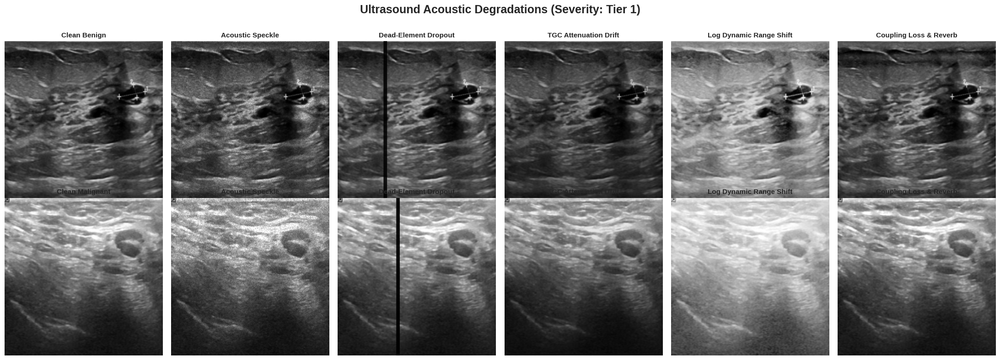

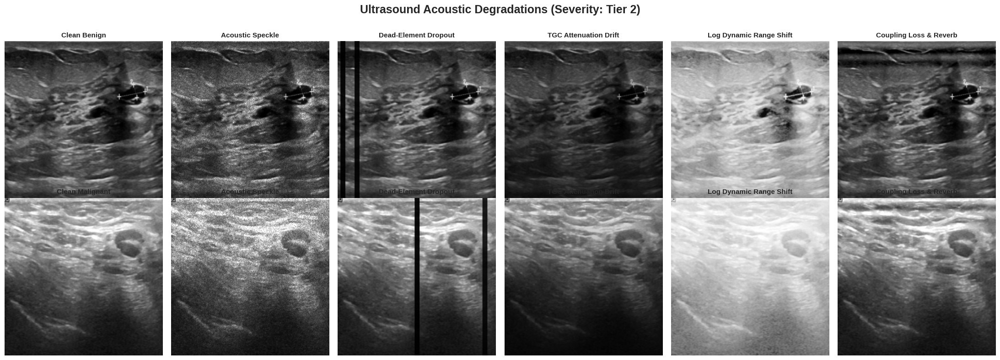

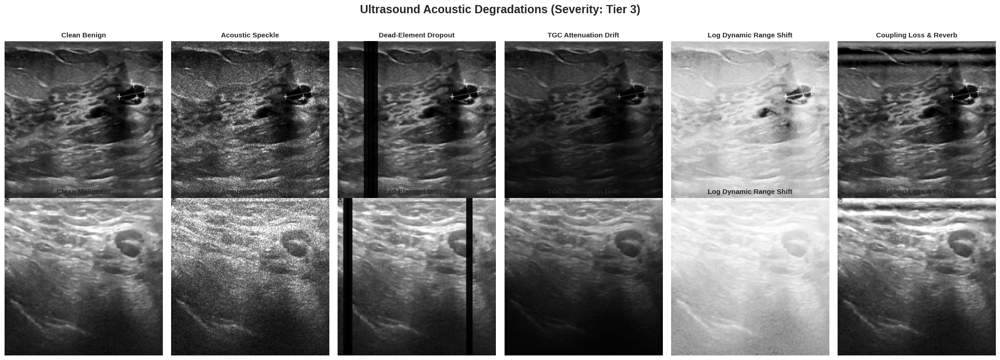

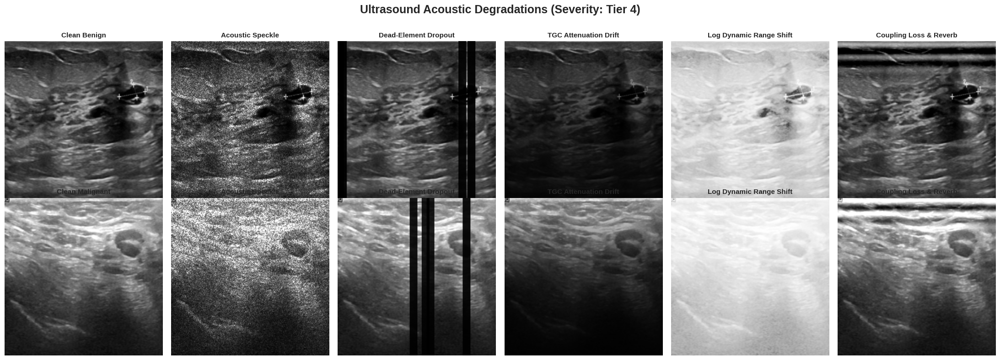

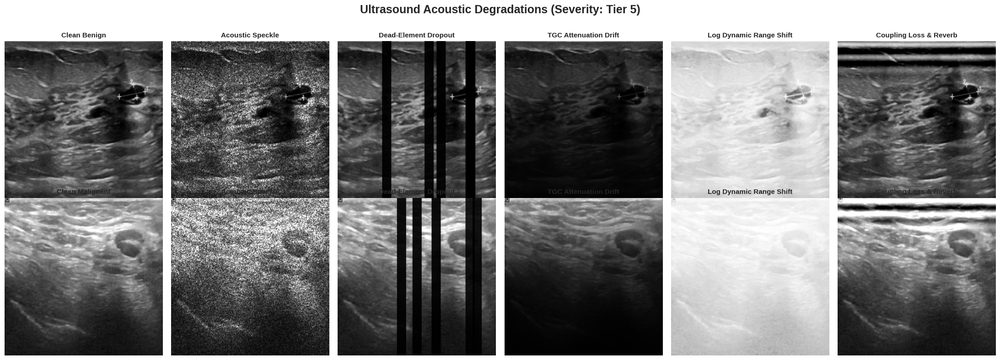

In [18]:
def denormalize(tensor_img):
    """Helper to convert standard ImageNet normalized tensor back to un-normalized [0, 1] range"""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    unnorm = tensor_img.cpu() * std + mean
    return torch.clamp(unnorm, 0.0, 1.0)

# Select 1 benign and 1 malignant sample scan from our stratified test dataframe
benign_sample_path = test_df[test_df['label'] == 0].iloc[0]['filepath']
malignant_sample_path = test_df[test_df['label'] == 1].iloc[0]['filepath']

# Prepare pipeline transformations
pil_to_tensor = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# Load images
img_benign = pil_to_tensor(Image.open(benign_sample_path).convert('RGB')).unsqueeze(0)
img_malignant = pil_to_tensor(Image.open(malignant_sample_path).convert('RGB')).unsqueeze(0)

# Instantiate the physics engine
physics_engine = UltrasoundClinicalPhysicsEngine()

# Set severities for comparative visual grid (e.g., Tier 3 and Tier 5)
severities = [1, 2, 3, 4, 5]

for sev in severities:
    fig, axes = plt.subplots(2, 6, figsize=(22, 8))
    plt.suptitle(f"Ultrasound Acoustic Degradations (Severity: Tier {sev})", fontsize=18, fontweight='bold', y=0.98)

    distortions_lbls = [
        "Pristine",
        "Acoustic Speckle",
        "Dead-Element Dropout",
        "TGC Attenuation Drift",
        "Log Dynamic Range Shift",
        "Coupling Loss & Reverb"
    ]

    # Run Benign (Row 1) & Malignant (Row 2)
    for row_idx, (img, label_name) in enumerate(zip([img_benign, img_malignant], ["Benign", "Malignant"])):
        # Original (No distortion)
        axes[row_idx, 0].imshow(img.squeeze().permute(1, 2, 0).numpy())
        axes[row_idx, 0].set_title(f"Clean {label_name}", fontsize=11, fontweight='bold')
        axes[row_idx, 0].axis('off')

        # Distortions 1 to 5
        for dist_idx in range(1, 6):
            distorted_tensor = physics_engine(img, distortion_idx=dist_idx, tier=sev)
            img_np = distorted_tensor.squeeze().permute(1, 2, 0).numpy()

            axes[row_idx, dist_idx].imshow(img_np)
            axes[row_idx, dist_idx].set_title(f"{distortions_lbls[dist_idx]}", fontsize=11, fontweight='bold')
            axes[row_idx, dist_idx].axis('off')

    plt.tight_layout()
    plt.subplots_adjust(top=0.88)
    plt.show()

### 8.1 Standard Image Distortions for Comparison

To prove whether our model is specifically vulnerable to ultrasound physics, we need a control group to compare it against. Standard computer vision research usually tests image models using picture flaws listed below.

We built a second testing tool that applies five traditional computer vision flaws across the exact same five intensity levels. This lets us see whether the network struggles with general image blur and digital static, or if real medical ultrasound issues cause unique failure patterns that standard tests completely miss.

**1. Additive White Gaussian Noise (AWGN):**
  A standard digital image corruption that sprinkles uniform electronic static evenly across the entire image. We use this control to see if random pixel-level noise affects the model the same way as structured acoustic speckle.

**2. Salt & Pepper Noise (Impulse Noise):**
  Randomly flips individual pixels into pure white or pure black dots, mimicking transmission errors or dead pixels on a display screen.

**3. Out-of-Focus Gaussian Blur:**
  Softens the whole picture like an out-of-focus camera lens, blurring fine details and gradients to test how the model behaves when sharp tumor boundaries disappear.

**4. JPEG Compression Blocking Artifacts:**
  Squeezes file size by turning smooth gradients into blocky pixel squares. This simulates what happens when medical scans are compressed for telemedicine or sent over slow hospital networks.

**5. Camera Motion Blur:**
  Smears pixels horizontally in a straight line, mimicking what happens when a camera shakes during an exposure.

This tool uses the exact same layout as our ultrasound physics engine, allowing us to swap between realistic hospital equipment flaws and standard computer vision benchmarks without changing any of our evaluation code.

In [19]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms.functional as TF

class ClassicalCVDistortionEngine(nn.Module):
    def __init__(self):
        super(ClassicalCVDistortionEngine, self).__init__()

    def apply_gaussian_noise(self, x, tier=3):
        """
        Distortion 1: Additive White Gaussian Noise (AWGN)
        """
        sigmas = {1: 0.015, 2: 0.035, 3: 0.06, 4: 0.10, 5: 0.15}
        sigma = sigmas.get(tier, 0.06)

        B, C, H, W = x.shape
        # Sample (B, 1, H, W) to keep noise grayscale rather than rainbow RGB
        noise = torch.randn((B, 1, H, W), device=x.device) * sigma
        return torch.clamp(x + noise, 0.0, 1.0)

    def apply_salt_and_pepper(self, x, tier=3):
        """
        Distortion 2: Salt & Pepper Noise (Impulse Noise)
        """
        probabilities = {1: 0.002, 2: 0.006, 3: 0.015, 4: 0.03, 5: 0.06}
        prob = probabilities.get(tier, 0.015)

        B, C, H, W = x.shape
        x_out = x.clone()

        # Generate 1-channel masks and expand across all 3 RGB channels
        rand_grid = torch.rand((B, 1, H, W), device=x.device)
        salt_mask = (rand_grid < (prob / 2.0)).expand_as(x)
        pepper_mask = (rand_grid > (1.0 - prob / 2.0)).expand_as(x)

        x_out[salt_mask] = 1.0
        x_out[pepper_mask] = 0.0
        return x_out

    def apply_gaussian_blur(self, x, tier=3):
        """
        Distortion 3: Out-of-Focus Gaussian Blur
        """
        kernel_sizes = {1: 3, 2: 5, 3: 7, 4: 9, 5: 11}
        sigmas = {1: 0.5, 2: 1.0, 3: 1.5, 4: 2.2, 5: 3.0}

        k_size = kernel_sizes.get(tier, 7)
        sigma = sigmas.get(tier, 1.5)
        # Ensure kernel size is odd
        if k_size % 2 == 0:
            k_size += 1

        return TF.gaussian_blur(x, [k_size, k_size], [sigma, sigma])

    def apply_jpeg_compression(self, x, tier=3):
        """
        Distortion 4: JPEG Compression Blocking Artifacts
        """
        qualities = {1: 85, 2: 60, 3: 40, 4: 20, 5: 5}
        quality = qualities.get(tier, 40)

        B, C, H, W = x.shape
        x_out = x.clone()

        for b in range(B):
            # Transform single tensor to PIL image to apply JPEG simulation
            single_img = TF.to_pil_image(x[b])
            import io
            buffer = io.BytesIO()
            single_img.save(buffer, format="JPEG", quality=quality)
            buffer.seek(0)
            compressed_pil = Image.open(buffer)
            x_out[b] = TF.to_tensor(compressed_pil).to(x.device)

        return x_out

    def apply_motion_blur(self, x, tier=3):
        """
        Distortion 5: Camera Motion Blur (Linear Blur Filter)
        """
        kernel_sizes = {1: 3, 2: 5, 3: 7, 4: 11, 5: 15}
        k_size = kernel_sizes.get(tier, 7)

        # Create horizontal motion blur kernel
        kernel = torch.zeros((1, 1, k_size, k_size), device=x.device)
        kernel[0, 0, k_size // 2, :] = 1.0 / k_size

        # Convolve individually per channel
        B, C, H, W = x.shape
        # Pad boundaries helper
        pad = k_size // 2
        x_padded = torch.nn.functional.pad(x, (pad, pad, pad, pad), mode='replicate')

        x_out = torch.zeros_like(x)
        for c in range(C):
            x_out[:, c:c+1] = torch.nn.functional.conv2d(x_padded[:, c:c+1], kernel)

        return torch.clamp(x_out, 0.0, 1.0)

    def forward(self, x, distortion_idx, tier=3):
        if distortion_idx == 1:
            return self.apply_gaussian_noise(x, tier)
        elif distortion_idx == 2:
            return self.apply_salt_and_pepper(x, tier)
        elif distortion_idx == 3:
            return self.apply_gaussian_blur(x, tier)
        elif distortion_idx == 4:
            return self.apply_jpeg_compression(x, tier)
        elif distortion_idx == 5:
            return self.apply_motion_blur(x, tier)
        else:
            raise ValueError("distortion_idx must be between 1 and 5.")

print("ClassicalCVDistortionEngine initialized successfully.")

ClassicalCVDistortionEngine initialized successfully.


### 8.2 Checking the Standard Distortions

We plot the same clean benign and malignant scans from earlier through our standard computer vision flaws so we can compare them directly to our ultrasound tests.

Looking at these pictures side by side highlights how ordinary digital camera noise affects medical scans differently than ultrasound physics.

Plotting these comparison grids lets us visually confirm that our control tests are working properly before we run full evaluations across all test patients.

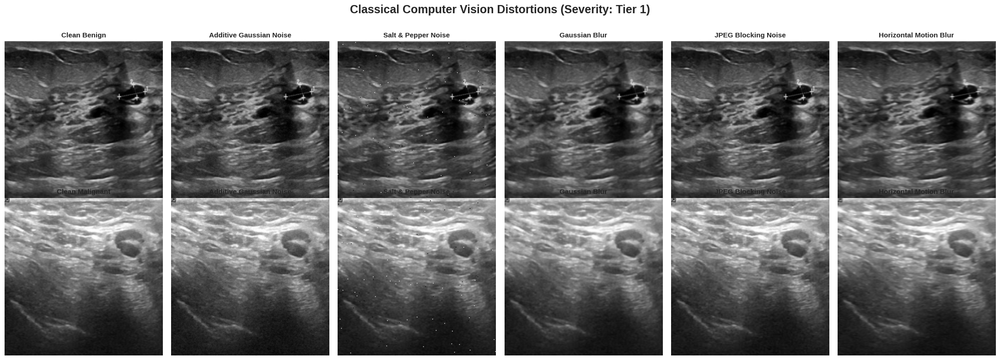

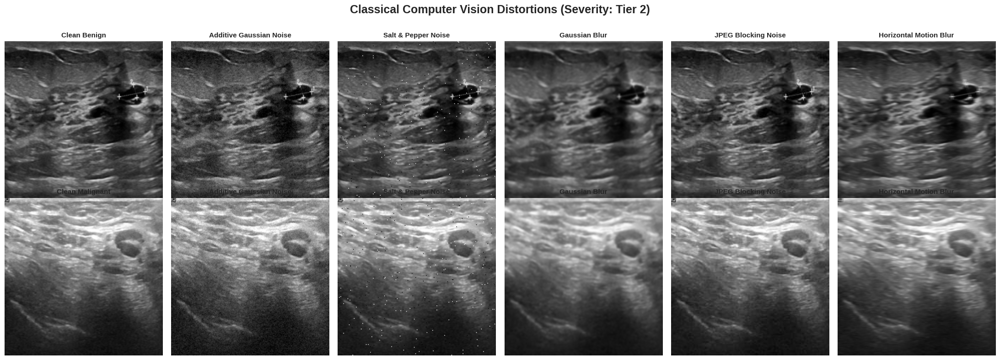

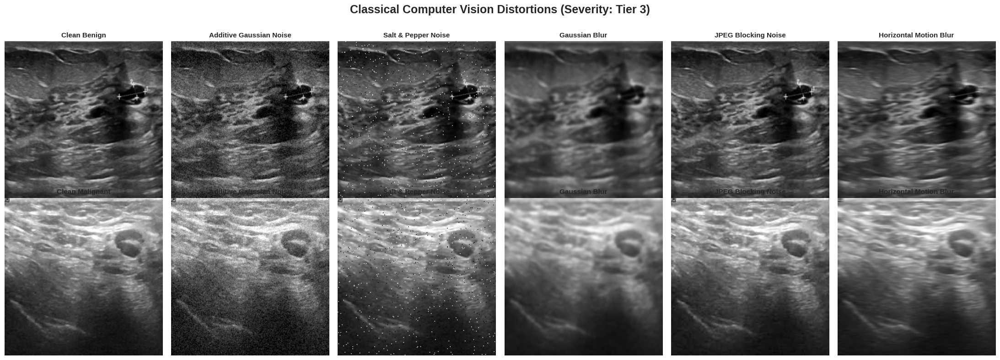

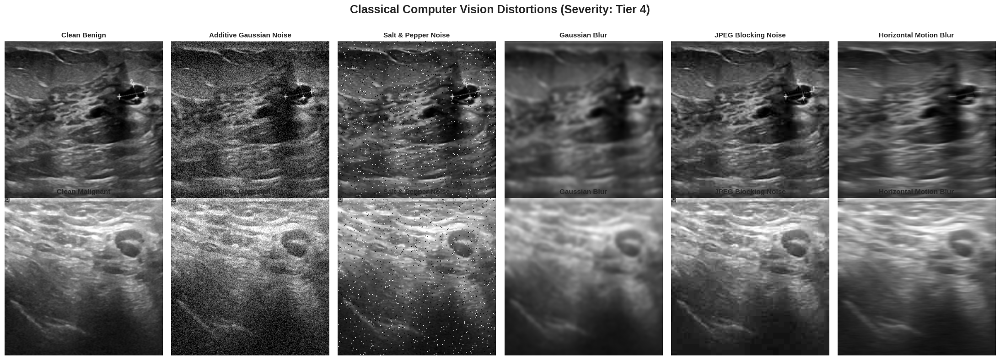

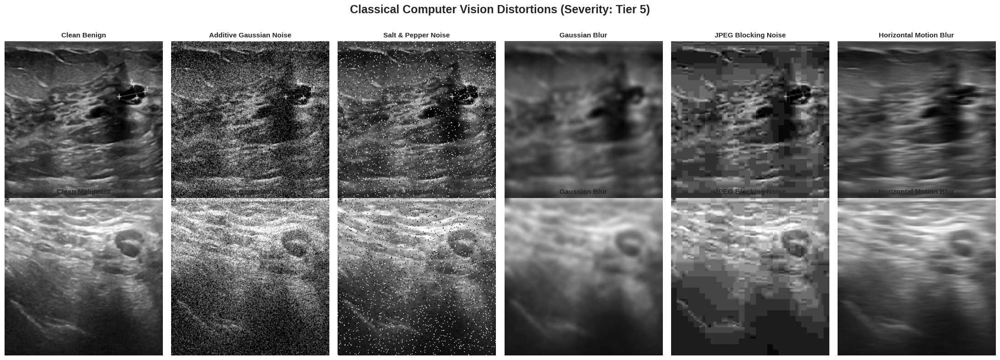

In [20]:
# Instantiate the classical CV distortion engine
classical_engine = ClassicalCVDistortionEngine()

# Visualize classical distortions on our benign and malignant test samples
for sev in range(1,6):
    fig, axes = plt.subplots(2, 6, figsize=(22, 8))
    plt.suptitle(f"Classical Computer Vision Distortions (Severity: Tier {sev})", fontsize=18, fontweight='bold', y=0.98)

    classical_lbls = [
        "Pristine",
        "Additive Gaussian Noise",
        "Salt & Pepper Noise",
        "Gaussian Blur",
        "JPEG Blocking Noise",
        "Horizontal Motion Blur"
    ]

    # Run Benign (Row 1) & Malignant (Row 2)
    for row_idx, (img, label_name) in enumerate(zip([img_benign, img_malignant], ["Benign", "Malignant"])):
        # Original (No distortion)
        axes[row_idx, 0].imshow(img.squeeze().permute(1, 2, 0).numpy())
        axes[row_idx, 0].set_title(f"Clean {label_name}", fontsize=11, fontweight='bold')
        axes[row_idx, 0].axis('off')

        # Classical Distortions 1 to 5
        for dist_idx in range(1, 6):
            distorted_tensor = classical_engine(img, distortion_idx=dist_idx, tier=sev)
            img_np = distorted_tensor.squeeze().permute(1, 2, 0).numpy()

            axes[row_idx, dist_idx].imshow(img_np)
            axes[row_idx, dist_idx].set_title(f"{classical_lbls[dist_idx]}", fontsize=11, fontweight='bold')
            axes[row_idx, dist_idx].axis('off')

    plt.tight_layout()
    plt.subplots_adjust(top=0.88)
    plt.show()

### 9 Stress-Testing the Model Across All 50 Conditions

Looking at individual sample images showed us what the distortions look like visually, but to measure their real impact, we need to evaluate how the model behaves across all **130 test patients**.

In this section, we run a systematic stress test across **50 distinct testing conditions**:
* **10 Total Noise Sources:** Our 5 realistic ultrasound hardware flaws alongside our 5 standard computer vision control flaws.
* **5 Severity Tiers:** Ranging from Tier 1 (mild image degradation) to Tier 5 (severe equipment or signal failure).

#### How the Evaluation Pipeline Works
To ensure our noise math acts on realistic image brightness, the evaluation loop executes three steps directly on the GPU for every batch of test scans:
1. **Un-normalize:** Reverses the ResNet-18 normalization math so pixel values return to a standard `0.0` to `1.0` brightness scale.
2. **Inject Distortion:** Passes the clean scan through the selected noise source and severity level.
3. **Re-normalize & Predict:** Re-applies the standard normalization math and feeds the degraded image into our frozen ResNet-18 model to record its diagnosis.

#### What We Track
Across every noise type and severity tier, we track three core metrics side-by-side to get a complete picture of how the AI breaks down:
* **Accuracy (*Higher is better*):** The overall percentage of correct predictions across all 130 scans.
* **False Negative Rate / FNR (*Lower is better*):** The percentage of actual cancers that the model misses (silently misclassifying malignant tumors as benign).
* **False Positive Rate / FPR (*Lower is better*):** The percentage of harmless benign scans that the model falsely flags as cancer (triggering unnecessary alarms and biopsies).

In [21]:
import pandas as pd
import numpy as np
import torch
from sklearn.metrics import confusion_matrix, auc, accuracy_score, recall_score

def evaluate_distortion_engine(model, engine, distortion_mapping, test_loader, device, mean_t, std_t):
    """Runs systematic stress testing for a given distortion engine."""
    stress_results = []
    model.eval()

    for dist_name, dist_idx in distortion_mapping.items():
        for tier in range(1, 6):
            y_true, y_pred, y_prob = [], [], []
            with torch.no_grad():
                for inputs, labels in test_loader:
                    inputs = inputs.to(device)

                    # Step A: Denormalize back to physical [0, 1] range
                    raw_inputs = torch.clamp(inputs * std_t + mean_t, 0.0, 1.0)

                    # Step B: Apply distortion
                    corrupted_raw = engine(raw_inputs, distortion_idx=dist_idx, tier=tier)

                    # Step C: Re-normalize
                    corrupted_norm = (corrupted_raw - mean_t) / std_t

                    outputs = model(corrupted_norm)
                    probs = torch.softmax(outputs, dim=1)

                    y_true.extend(labels.numpy())
                    y_pred.extend(torch.argmax(probs, dim=1).cpu().numpy())
                    y_prob.extend(probs[:, 1].cpu().numpy())

            y_true, y_pred, y_prob = np.array(y_true), np.array(y_pred), np.array(y_prob)
            tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
            acc = accuracy_score(y_true, y_pred)
            sens = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
            spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0

            stress_results.append({
                'Distortion': dist_name,
                'Severity_Tier': tier,
                'Accuracy': acc,
                'Sensitivity': sens,
                'Specificity': spec,
                'FNR': 1.0 - sens,
                'FPR': 1.0 - spec,
            })

    return pd.DataFrame(stress_results)

Running the evals

In [22]:
mean_t = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std_t = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

# Re-instantiate the engines
physics_engine = UltrasoundClinicalPhysicsEngine().to(device)
classical_engine = ClassicalCVDistortionEngine().to(device)

# Define mappings for each engine
clinical_mapping = {
    'Multiplicative Speckle': 1,
    'Dead Element Dropout': 2,
    'TGC Attenuation Drift': 3,
    'Dynamic Range Shift': 4,
    'Reverberation Contact Loss': 5
}

classical_mapping = {
    'Additive Gaussian Noise': 1,
    'Salt & Pepper Noise': 2,
    'Gaussian Blur': 3,
    'JPEG Blocking Noise': 4,
    'Horizontal Motion Blur': 5
}

# Run evaluations
print("Evaluating Clinical Ultrasound Distortions...")
clinical_df = evaluate_distortion_engine(model, physics_engine, clinical_mapping, test_loader, device, mean_t, std_t)
clinical_df['Engine'] = 'Clinical'

print("Evaluating Classical CV Distortions...")
classical_df = evaluate_distortion_engine(model, classical_engine, classical_mapping, test_loader, device, mean_t, std_t)
classical_df['Engine'] = 'Classical CV'

# Combine results
combined_stress_df = pd.concat([clinical_df, classical_df], ignore_index=True)
print("Evaluation complete!")

Evaluating Clinical Ultrasound Distortions...
Evaluating Classical CV Distortions...
Evaluation complete!


Visualization

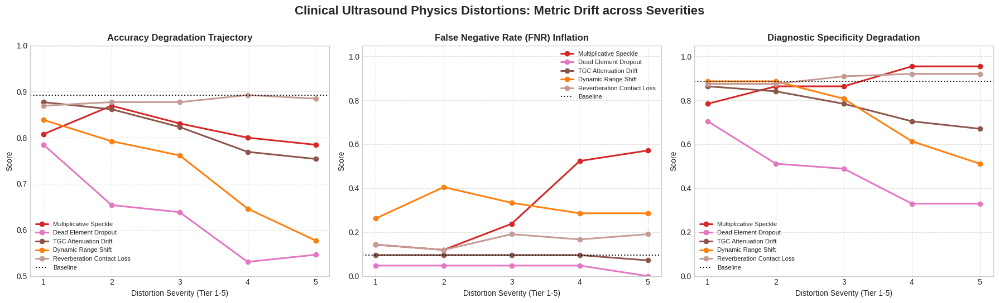

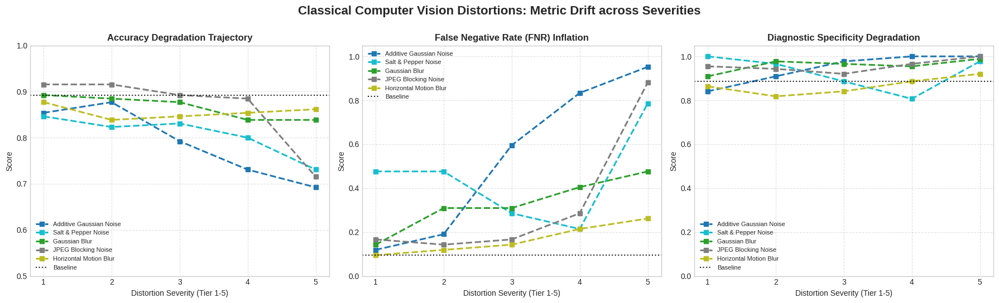

In [33]:
import matplotlib.pyplot as plt
import numpy as np

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Extract baseline metrics from the baseline_metrics dict computed in cell tqpEfrU2Mkco
base_acc = baseline_metrics['accuracy']
base_fnr = baseline_metrics['fnr']
base_spec = baseline_metrics['specificity']

# Metric configurations for the plots (excluding ROC_AUC) with locked y-limits (ymin, ymax)
metrics_config = [
    ('Accuracy', 'Accuracy Degradation Trajectory', base_acc, (0.5, 1.0)),
    ('FNR', 'False Negative Rate (FNR) Inflation', base_fnr, (0.0, 1.05)),
    ('Specificity', 'Diagnostic Specificity Degradation', base_spec, (0.0, 1.05))
]

# Unique distortions for each engine
clinical_dists = combined_stress_df[combined_stress_df['Engine'] == 'Clinical']['Distortion'].unique()
classical_dists = combined_stress_df[combined_stress_df['Engine'] == 'Classical CV']['Distortion'].unique()

# Color palettes for clean plotting
clinical_colors = ['#d62728', '#e377c2', '#8c564b', '#ff7f0e', '#c49c94']
classical_colors = ['#1f77b4', '#17becf', '#2ca02c', '#7f7f7f', '#bcbd22']

# =========================================================================
# FIGURE 1: Clinical Ultrasound Physics Distortions
# =========================================================================
fig1, axes1 = plt.subplots(1, 3, figsize=(18, 5.5))
fig1.suptitle("Clinical Ultrasound Physics Distortions: Metric Drift across Severities", fontsize=16, fontweight='bold', y=0.98)

for idx, (col_name, title, baseline, ylims) in enumerate(metrics_config):
    ax = axes1[idx]

    # Plot only Clinical Distortions
    for c_idx, dist_name in enumerate(clinical_dists):
        subset = combined_stress_df[(combined_stress_df['Distortion'] == dist_name) & (combined_stress_df['Engine'] == 'Clinical')]
        ax.plot(subset['Severity_Tier'], subset[col_name], 'o-', label=dist_name, color=clinical_colors[c_idx], linewidth=2.2)

    # Baseline reference line
    ax.axhline(y=baseline, color='black', linestyle=':', alpha=0.9, label='Baseline')

    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Distortion Severity (Tier 1-5)', fontsize=10)
    ax.set_ylabel('Score', fontsize=10)
    ax.set_xticks(range(1, 6))
    ax.set_ylim(ylims)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(fontsize=8, loc='best')

plt.tight_layout()
plt.subplots_adjust(top=0.85)
plt.show()

# =========================================================================
# FIGURE 2: Classical Computer Vision Distortions
# =========================================================================
fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5.5))
fig2.suptitle("Classical Computer Vision Distortions: Metric Drift across Severities", fontsize=16, fontweight='bold', y=0.98)

for idx, (col_name, title, baseline, ylims) in enumerate(metrics_config):
    ax = axes2[idx]

    # Plot only Classical CV Distortions
    for c_idx, dist_name in enumerate(classical_dists):
        subset = combined_stress_df[(combined_stress_df['Distortion'] == dist_name) & (combined_stress_df['Engine'] == 'Classical CV')]
        ax.plot(subset['Severity_Tier'], subset[col_name], 's--', label=dist_name, color=classical_colors[c_idx], linewidth=2.2)

    # Baseline reference line
    ax.axhline(y=baseline, color='black', linestyle=':', alpha=0.9, label='Baseline')

    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Distortion Severity (Tier 1-5)', fontsize=10)
    ax.set_ylabel('Score', fontsize=10)
    ax.set_xticks(range(1, 6))
    ax.set_ylim(ylims)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(fontsize=8, loc='best')

plt.tight_layout()
plt.subplots_adjust(top=0.85)
plt.show()

### 10 Interpretation and analysis

Looking at individual sample images showed us what the flaws look like visually, but our systematic evaluation across all **130 test patients** reveals how the frozen ResNet-18 model actually behaves under all **five clinical ultrasound hardware flaws (Figure 1)** and **five classical computer vision controls (Figure 2)** across five severity tiers (50 total testing conditions).

---

### What the results reveal: Two opposite ways medical AI fails

Tracking **Accuracy**, **False Negative Rate (FNR-Missed Cancers)**, and **Specificity (Benign Clearance Rate)** side-by-side demonstrates why relying on top-line accuracy is so dangerous in healthcare. Depending on which physical flaw hits the ultrasound scanner in **Figure 1**, our model breaks down in two completely opposite directions:

#### 1. Silent missed cancers & the "accuracy illusion" (Speckle & poor gel contact)
* **Multiplicative speckle (red curve):** As grainy acoustic texture increases from Tier 1 to Tier 5, overall **Accuracy** only drops moderately,still scoring a respectable looking **~78.5%** at Tier 5, while **Specificity** climbs to **98%**. However, looking at the middle panel (**FNR**) exposes a severe hidden failure: **missed cancers skyrocket from 9.5% to 62%**. Because heavy grain obscures the jagged borders of malignant tumors, the uncertain model defaults to guessing the majority class ("Benign"). Since roughly two-thirds of our test patients are benign (67.7%), guessing "Benign" keeps overall accuracy artificially high while silently missing nearly two-thirds of active cancers.
* **Reverberation contact loss (tan curve):** When poor gel contact creates bright horizontal bands near the top of the scan, overall **Accuracy** barely moves (~88-89%). Yet the **False Negative Rate quietly doubles (from 9.5% to ~19%)** because tumors located shallowly near the skin are masked by the bright reverberation glare.

#### 2. False-alarm cascades & "alert fatigue" (Probe dropout, TGC drift, & vendor contrast)
While grain and glare cause the model to miss cancers, hardware shadow artifacts trigger the exact opposite failure mode in **Figure 1, Panel 3 (Specificity)**:
* **Dead-element dropout (pink) & TGC attenuation drift (brown):** In real breast ultrasounds, dense cancerous tumors block sound waves and cast dark acoustic shadows underneath them, whereas harmless fluid-filled cysts let sound pass through. When broken probe sensors create **dark vertical dropout stripes** or miscalibrated **TGC dials darken the bottom of the scan**, the network mistakes those artificial dark regions for malignant tumor shadows. As a result, **Specificity plunges to 32% under probe dropout and 67% under TGC drift**, meaning the AI falsely flags up to **68% of healthy benign patients as having cancer**.
* **Dynamic range shift (orange):** Simulating a software contrast shift between different ultrasound vendors causes both failure modes across different tiers: jumping into the **40% missed-cancer Danger Zone at Tier 2**, and then collapsing **Specificity down to 51% at Tier 5**.

#### 3. Why standard computer vision benchmarks are not enough (Figure 2 vs. Figure 1)
Comparing **Figure 2 (Classical CV Distortions)** against **Figure 1 (Clinical Ultrasound Distortions)** proves why medical AI must be stress-tested using domain-specific physics:
* Under generic digital corruptions in **Figure 2** (*Additive Gaussian Noise*, *JPEG Blocking*, *Gaussian Blur*, and *Salt & Pepper Noise*), the model fails almost exclusively in **one direction**: as fine edge details are blurred or pixelated at Tiers 4–5, the network simply defaults to predicting "Benign." **Specificity approaches 98%–100%**, **FNR climbs to 48%–93%**, and **Accuracy settles near the ~69%–73% majority-class floor**.
* If hospital evaluators only tested this model using standard computer vision noise (Figure 2), they would never discover the **Specificity collapse and false-positive cascades** revealed by our ultrasound physics engine in Figure 1. Generic camera noise destroys texture, but it does not replicate the structured acoustic shadowing of a damaged piezoelectric transducer or a miscalibrated TGC curve.

---

### Final takeaway: Connecting back to my AP research paper

This computational experiment provides direct empirical proof for the three core themes of my *Student Sphere* integrative review:
1. **The benchmark illusion:** A model that achieves **89.2% accuracy** and **90.5% sensitivity** on clean benchmark scans can still present severe clinical blind spots when exposed to routine hospital equipment variations.
2. **Silent failure vs. alert fatigue:** Standard deep learning models cannot quantify their own uncertainty or warn a clinician when image quality degrades. Depending on the physical artifact, the AI either **fails silently** by labeling aggressive tumors as harmless cysts (up to 62% missed cancers under heavy speckle) or triggers **waves of false alarms** (up to 68% false positives when broken probe elements mimic tumor shadows), directly driving radiologist alert fatigue.
3. **Why AI cannot replace radiologists:** A convolutional neural network only processes pixel intensities; it has no physical awareness that a technician applied insufficient coupling gel or that a dropped ultrasound probe has dead piezoelectric elements. Human radiologists remain indispensable to recognize physical hardware artifacts, prevent unnecessary biopsies, and utilize AI safely as a **reciprocal digital safety net** rather than an autonomous replacement.